# Análisis de Datos II
### Pablo Salvagni

## Consigna

### Actividad 4. Feature engineering avanzado, prevención de data leakage, auditoría de sesgos y documentación

Descargar el siguiente dataset:

https://drive.google.com/file/d/1Od_naN-d1B_mjJeIMDlL1dTvHEDX9PO6/view?usp=drive_link

El objetivo es predecir el ingreso anual de cada persona (`income`) a partir de sus características (edad, horas trabajadas por semana, nivel educativo, tipo de empleador, estado civil, sexo, raza y si nació en EE. UU.).

---

### Parte 1: feature engineering avanzado y prevención de data leakage

**a)** Analizar la distribución de la target (histograma y skewness). Si aplica, realizar una de las transformaciones vistas en clase (log, Box-Cox o Yeo-Johnson) y explicar cuál se eligió y por qué. Comparar la distribución de la target original con la transformada.

**b)** Armar un modelo de regresión lineal que implemente k-fold cross validation sin data leakage.

**c)** Si aplica, evaluar el MAE del modelo entrenado con la target original y con la target transformada. Comentar los resultados.

### Parte 2: auditoría de sesgos y documentación

**a)** Evaluar el rendimiento del modelo final considerando al menos una variable sensible (por ejemplo, `sex` o `race`). Calcular métricas de error (como MAE) por subgrupo y analizar si existen disparidades o sesgos en las predicciones.

**b)** Redactar una Model Card breve para el modelo final entrenado, que indique el propósito, entradas/salidas, métricas de desempeño global y por subgrupo según las variables sensibles analizadas, y limitaciones de uso.

---

**Forma de entrega.** Enlace a una notebook en un repositorio de acceso público. Lo importante es que el código esté ejecutado (que muestre la salida).

**Evaluación**

- Se evaluará que se haya respetado la consigna y que haya una interpretación adecuada de los resultados.
- Cada respuesta debe estar justificada mediante evidencia obtenida a partir de las herramientas y métricas utilizadas.

In [3]:
# librerias para la parte 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

#### 1. Importación de dataset

El dataset es una versión del censo de ingresos de EE. UU. donde cada fila es **una persona** y el objetivo ES UN problema de **regresión**: se busca predecir el ingreso anual `income` (en dólares) a partir de 8 características.

| columna | tipo | descripción |
|---|---|---|
| `age` | numérica | edad |
| `hours_per_week` | numérica | horas trabajadas por semana |
| `education` | categórica | nivel educativo |
| `employer_type` | categórica | tipo de empleador |
| `marital_status` | categórica | estado civil |
| `sex` | categórica (sensible) | sexo |
| `race` | categórica (sensible) | raza |
| `born_in_us` | categórica | nació en EE. UU. (Yes/No) |
| `income` | numérica | **target**: ingreso anual |

#REVISAR`sex` y `race` son las variables sensibles que vamos a auditar en la Parte 2, así que entran como features del modelo desde la Parte 1.

In [4]:
# cargo el dataset desde archivo local
df = pd.read_csv('dataset/census_income.csv')
print('shape:', df.shape)
df.head()

shape: (10000, 9)


,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.0,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,279000.0
1,20,35.0,High school,Private,Never married,Female,White,Yes,23000.0
2,59,30.0,High school,State government,Divorced,Female,White,Yes,15100.0
3,43,40.0,Some college,State government,Married,Male,Black,Yes,31200.0
4,33,20.0,No high school diploma,Private,Married,Female,Black,Yes,9400.0


#### 2. Mini EDA

Reviso estructura, tipos, faltantes y distribución de cada variable antes de modelar.

In [ ]:
# estructura y tipos
print(df.info())
print('\nFaltantes por columna:')
print(df.isnull().sum())

# evito la notación científica y uso separador de miles en los float para mejor visualizacion de datos.
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

# resumen rápido de la target en valores legibles
print(f"\nincome -> media: {df['income'].mean():,.0f} | mediana: {df['income'].median():,.0f} | "
      f"min: {df['income'].min():,.0f} | max: {df['income'].max():,.0f}")

print('\nDescripción de las numéricas:')
# transpongo (una fila por variable) y renombro el percentil 50 como 'mediana'
df.describe().T.rename(columns={'50%': 'mediana'})

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             10000 non-null  int64  
 1   hours_per_week  9500 non-null   float64
 2   education       9700 non-null   str    
 3   employer_type   9600 non-null   str    
 4   marital_status  10000 non-null  str    
 5   sex             10000 non-null  str    
 6   race            10000 non-null  str    
 7   born_in_us      10000 non-null  str    
 8   income          10000 non-null  float64
dtypes: float64(2), int64(1), str(6)
memory usage: 1.1 MB
None

Faltantes por columna:
age                 0
hours_per_week    500
education         300
employer_type     400
marital_status      0
sex                 0
race                0
born_in_us          0
income              0
dtype: int64

income -> media: 54,407 | mediana: 36,400 | min: 110 | max: 1,096,000

Descripción de las numéricas:


,count,mean,std,min,25%,mediana,75%,max
age,"10,000.0",42.8,14.9,17.0,30.0,43.0,55.0,92.0
hours_per_week,"9,500.0",39.1,12.9,1.0,36.0,40.0,45.0,99.0
income,"10,000.0","54,406.8","68,071.3",110.0,"19,000.0","36,400.0","65,000.0","1,096,000.0"


In [21]:
# distribución de las variables categóricas
cat_cols = ['education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']
for col in cat_cols:
    print('-------------------------------------')
    print(f'--- {col} ---')
    print('-------------------------------------')
    print(df[col].value_counts(dropna=False))
    print()

-------------------------------------
--- education ---
-------------------------------------
education
High school               2386
Some college              2160
Bachelor degree           2106
Graduate degree           1383
No high school diploma     848
Associate degree           817
NaN                        300
Name: count, dtype: int64

-------------------------------------
--- employer_type ---
-------------------------------------
employer_type
Private                         6509
Private non-profit               639
Local government                 622
Self-employed                    532
State government                 495
Self-employed (incorporated)     433
NaN                              400
Federal government               339
Unpaid family work                31
Name: count, dtype: int64

-------------------------------------
--- marital_status ---
-------------------------------------
marital_status
Married          5461
Never married    3037
Divorced         1123


### Conclusión del mini EDA

- El dataset cuenta con **10.000** filas y **9** columnas: 2 features numéricas (`age`, `hours_per_week`), 6 categóricas y la target `income`.
- **Faltantes**: `hours_per_week` (500), `education` (300) y `employer_type` (400).
- `income` va de **110** a **1.096.000** con media (~54k) muy por encima de la mediana (~36k): es una target **muy asimétrica a la derecha**. Analizar si es cadidata a aplicarle una transformación.
- `sex` y `race` tienen subgrupos con tamaños distintos, son caracteristicas a tener en cuenta para una posible auditoria mas adelante.
- Todos los valores de `income` son **positivos** (min 110 > 0), así que log y Box-Cox son aplicables.

## Parte 1: feature engineering avanzado y prevención de data leakage

### 1.a Distribución de la target y transformación

Imprimo un histograma y la skewness de `income`. Si la asimetría es grande, pruebo las transformaciones vistas en clase (log, Box-Cox, Yeo-Johnson) y me quedo con la que deje la skewness más cerca de 0.

Skewness de income (original): 4.453


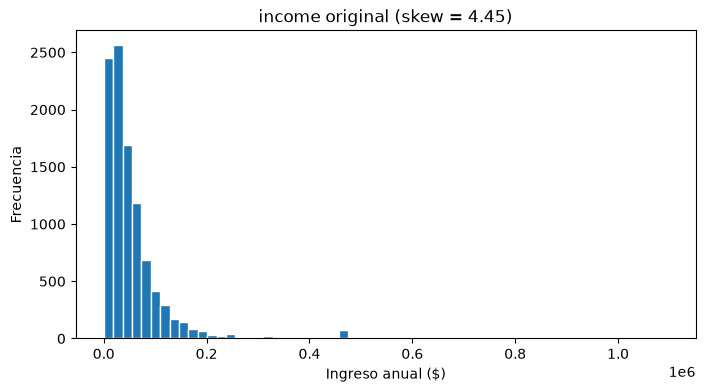

In [7]:
y = df['income'].astype(float)
print(f'Skewness de income (original): {skew(y):.3f}')

plt.figure(figsize=(8, 4))
plt.hist(y, bins=60, edgecolor='white')
plt.title(f'income original (skew = {skew(y):.2f})')
plt.xlabel('Ingreso anual ($)')
plt.ylabel('Frecuencia')
plt.show()

Skewness original          : 4.453
Skewness log               : -1.011
Skewness Box-Cox (λ=0.214) : 0.055
Skewness Yeo-Johnson (λ=0.214) : 0.055


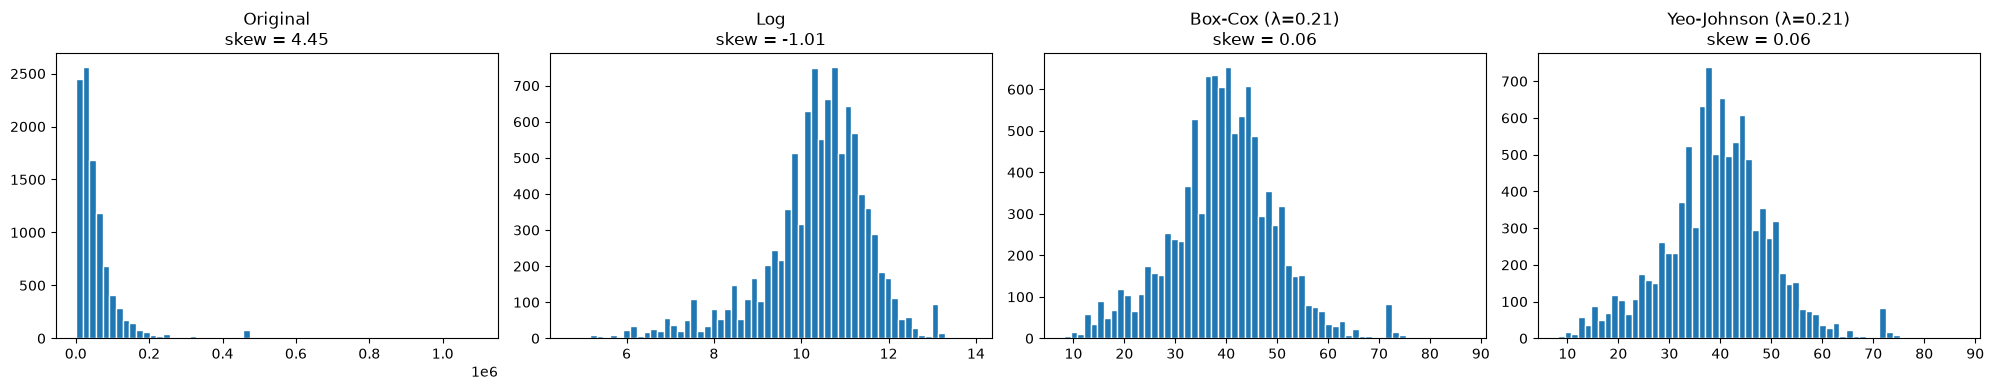

In [ ]:
# Comparo las 3 transformaciones de la consigna y vistas en clase, log, box-cox y yeo-johnson.
y_log = np.log(y)

bc = PowerTransformer(method='box-cox', standardize=False)  # standardize=False: no hace falta en la target
y_bc = bc.fit_transform(y.values.reshape(-1, 1)).ravel()

yj = PowerTransformer(method='yeo-johnson', standardize=False)
y_yj = yj.fit_transform(y.values.reshape(-1, 1)).ravel()

print(f'Skewness original          : {skew(y):.3f}')
print(f'Skewness log               : {skew(y_log):.3f}')
print(f'Skewness Box-Cox (λ={bc.lambdas_[0]:.3f}) : {skew(y_bc):.3f}')
print(f'Skewness Yeo-Johnson (λ={yj.lambdas_[0]:.3f}) : {skew(y_yj):.3f}')

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, datos, titulo in zip(
    axes,
    [y, y_log, y_bc, y_yj],
    ['Original', 'Log', f'Box-Cox (λ={bc.lambdas_[0]:.2f})', f'Yeo-Johnson (λ={yj.lambdas_[0]:.2f})'],
):
    ax.hist(datos, bins=60, edgecolor='white')
    ax.set_title(f'{titulo}\nskew = {skew(datos):.2f}')
plt.tight_layout()
plt.show()

### Conclusión 1.a

- `income` original tiene skewness **≈ 4.45**: fuerte cola a la derecha, como se veía en el histograma.
- **Log** la corrige pero **se pasa**: deja skew **≈ −1.01** (ahora cola a la izquierda). Como lo visto en las notebook de clases, ante asimetría muy marcada, el log puede sobre-corregir.
- **Box-Cox** y **Yeo-Johnson** eligen λ automáticamente (λ ≈ **0.21**) y dejan la distribución casi simétrica (skew **≈ 0.05**). Como `income` es estrictamente positivo, ambas dan el mismo resultado.
- **Elijo Box-Cox**: parece ser la que mejor simetriza (skew ≈ 0, mejor que log) y es válida porque la target es positiva. En la regresión, la aplico con `TransformedTargetRegressor`, ajustando λ **dentro de cada fold** para no filtrar información.

### 1.b Regresión lineal con k-fold sin data leakage

Armo una regresión lineal con **5-fold cross validation**. Para evitar data leakage, **todo** el preprocesamiento (imputación, estandarización, one-hot) va dentro de un `Pipeline`, de modo que `cross_validate` lo **re-ajusta solo con el train de cada fold** y nunca ve el test. Es el equivalente, en k-fold, del *"primero el split, después escalar/codificar"*.

In [9]:
X = df.drop(columns=['income'])
y = df['income'].astype(float)

num_cols = ['age', 'hours_per_week']
cat_cols = ['education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']

# preprocesamiento: imputar + escalar numéricas, imputar + one-hot categóricas
preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), cat_cols),
])

modelo_base = Pipeline([
    ('prep', preprocesador),
    ('lr', LinearRegression()),
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# MAE por fold (todo el preprocesamiento se ajusta solo con el train de cada fold)
res = cross_validate(modelo_base, X, y, cv=cv, scoring='neg_mean_absolute_error')
mae_folds = -res['test_score']
print('MAE por fold:', np.round(mae_folds, 2))
print(f'MAE promedio (target original): {mae_folds.mean():.2f} ± {mae_folds.std():.2f}')

MAE por fold: [30185.64 31570.62 31370.63 30299.41 32095.77]
MAE promedio (target original): 31104.42 ± 743.40


### 1.c MAE: target original vs. transformada

Comparo el MAE del mismo pipeline con la **target original** y con la **target transformada (Box-Cox)**. 

El MAE se mide siempre en **dólares**: `TransformedTargetRegressor` antitransforma la predicción automáticamente antes de calcular el error. 

Uso `cross_val_predict` para obtener las predicciones *out-of-fold* (cada fila predicha por un modelo que no la vio en el entrenamiento).

In [10]:
# modelo con la target transformada con Box-Cox (λ se ajusta dentro de cada fold)
modelo_bc = TransformedTargetRegressor(
    regressor=modelo_base,
    transformer=PowerTransformer(method='box-cox', standardize=False),
)

# predicciones out-of-fold con cada estrategia
pred_orig = cross_val_predict(modelo_base, X, y, cv=cv)
pred_bc = cross_val_predict(modelo_bc, X, y, cv=cv)

mae_orig = mean_absolute_error(y, pred_orig)
mae_bc = mean_absolute_error(y, pred_bc)

resumen = pd.DataFrame(
    {'MAE ($)': [mae_orig, mae_bc]},
    index=['Target original', 'Target Box-Cox'],
).round(2)
print(resumen)
print(f'\nMejora relativa con Box-Cox: {(mae_orig - mae_bc) / mae_orig * 100:.1f}%')

                 MAE ($)
Target original 31,104.4
Target Box-Cox  27,950.0

Mejora relativa con Box-Cox: 10.1%


### Conclusión de la Parte 1

- **Target**: `income` es muy asimétrica (skew ≈ 4.45). De las tres transformaciones, **Box-Cox** (λ ≈ 0.21) es la que mejor la simetriza (skew ≈ 0.05); el log sobre-corrige (skew ≈ −1.01). Se elige **Box-Cox**.
- **Sin leakage**: regresión lineal con `KFold(5)`. La imputación de faltantes, la estandarización y el one-hot van dentro del `Pipeline`, y la λ de Box-Cox dentro del `TransformedTargetRegressor`: todo se ajusta **solo con el train de cada fold**, nunca con el test.
- **MAE**: con la target original el MAE es **≈ 31.100 USD** y con Box-Cox baja a **≈ 27.950 USD** (~**10%** mejor). Transformar la target ayuda porque la regresión lineal minimiza el error cuadrático y, sobre una escala más simétrica, deja de estar dominada por los ingresos extremos.
- El **modelo con target Box-Cox** es el elegido y que pasa a la **Parte 2** del ejercicio (auditoría de sesgos y Model Card).

## Parte 2: auditoría de sesgos y documentación

### 2.1 Evaluar el rendimiento del modelo final considerando al menos una variable sensible (por ejemplo, `sex` o `race`). Calcular métricas de error (como MAE) por subgrupo y analizar si existen disparidades o sesgos en las predicciones.


### MAE por 'sex'
            MAE  sesgo_medio       n
sex                                 
Female 21,932.0     -7,537.0 4,864.0
Male   33,649.0    -12,810.0 5,136.0
MAE global: 27,950 | diferencia (max-min): 11,717 | ratio (min/max): 0.65 -> ALERTA

### MAE por 'race'
                       MAE  sesgo_medio       n
race                                           
Asian             32,760.0    -12,803.0   432.0
Black             19,619.0     -5,295.0 2,341.0
Other or multiple 19,015.0     -5,664.0   430.0
White             31,079.0    -12,077.0 6,797.0
MAE global: 27,950 | diferencia (max-min): 13,745 | ratio (min/max): 0.58 -> ALERTA


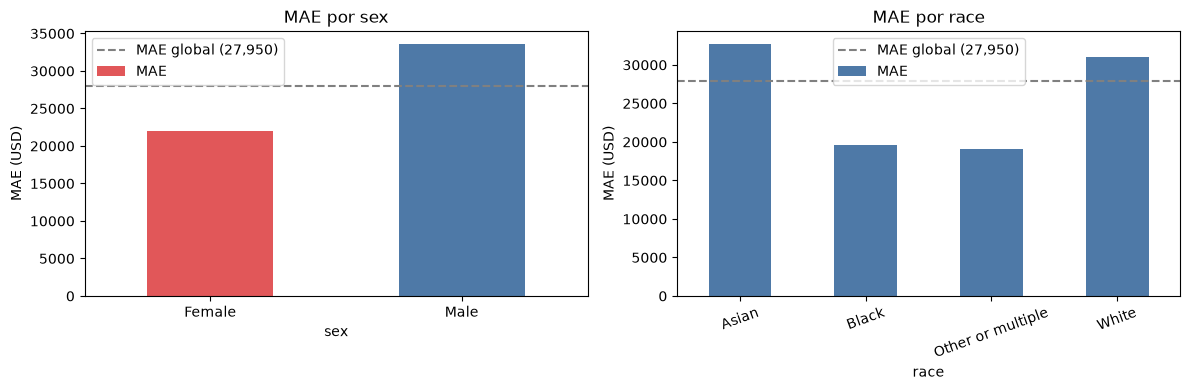

,Atributo,MAE diferencia,ratio (min/max),Resultado
0,sex,11717,0.7,ALERTA
1,race,13745,0.6,ALERTA


In [11]:
# Parte 2.a - Auditoría de sesgos: MAE por subgrupo con Fairlearn.
# Uso las predicciones out-of-fold del modelo final (target Box-Cox) de la Parte 1.
from fairlearn.metrics import MetricFrame, count

def sesgo_medio(y_true, y_pred):
    # error con signo: >0 el modelo sobreestima el ingreso del grupo, <0 lo subestima
    return np.mean(np.asarray(y_pred) - np.asarray(y_true))

metricas = {"MAE": mean_absolute_error, "sesgo_medio": sesgo_medio, "n": count}
UMBRAL_RATIO = 0.8  # convención (regla del 80%) tomada de la clase 8

def auditar(nombre, A):
    mf = MetricFrame(metrics=metricas, y_true=y, y_pred=pred_bc, sensitive_features=A)
    dif, ratio = mf.difference()["MAE"], mf.ratio()["MAE"]  # ratio = min/max
    print(f"\n### MAE por '{nombre}'")
    print(mf.by_group.round(0))
    print(f"MAE global: {mf.overall['MAE']:,.0f} | diferencia (max-min): {dif:,.0f} | "
          f"ratio (min/max): {ratio:.2f} -> {'OK' if ratio >= UMBRAL_RATIO else 'ALERTA'}")
    return mf, dif, ratio

mf_sex, dif_sex, ratio_sex = auditar("sex", df["sex"])
mf_race, dif_race, ratio_race = auditar("race", df["race"])

# gráfico de MAE por grupo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mf_sex.by_group["MAE"].plot.bar(ax=axes[0], color=["#E15759", "#4E79A7"], rot=0, title="MAE por sex")
mf_race.by_group["MAE"].plot.bar(ax=axes[1], color="#4E79A7", rot=20, title="MAE por race")
for ax in axes:
    ax.axhline(mae_bc, ls="--", color="gray", label=f"MAE global ({mae_bc:,.0f})")
    ax.set_ylabel("MAE (USD)"); ax.legend()
plt.tight_layout(); plt.show()

# tabla resumen con semáforo de equidad
resumen_fairness = pd.DataFrame([
    {"Atributo": "sex",  "MAE diferencia": round(dif_sex),  "ratio (min/max)": round(ratio_sex, 2),
     "Resultado": "OK" if ratio_sex  >= UMBRAL_RATIO else "ALERTA"},
    {"Atributo": "race", "MAE diferencia": round(dif_race), "ratio (min/max)": round(ratio_race, 2),
     "Resultado": "OK" if ratio_race >= UMBRAL_RATIO else "ALERTA"},
])
resumen_fairness

### 2.2  Redactar una Model Card breve para el modelo final entrenado, que indique el propósito, entradas/salidas, métricas de desempeño global y por subgrupo según las variables sensibles analizadas, y limitaciones de uso.

In [14]:
# Parte 2.b - Model Card con skops (como en la clase 8).
# Documento el modelo final (target Box-Cox) siguiendo los pasos de la consigna.
from pathlib import Path
from skops import card

carpeta_card = Path("model_card")
carpeta_card.mkdir(exist_ok=True)

# entreno el modelo final sobre TODO el dataset solo para documentarlo
modelo_bc.fit(X, y)
mc = card.Card(modelo_bc, template=None, model_diagram=False)

# Paso 1 - Propósito
mc.add(**{
    "Propósito": (
        "Modelo educativo (TP) para practicar feature engineering, prevención de data leakage "
        "y auditoría de sesgos. Estima el ingreso anual (`income`) de una persona a partir de "
        "datos del censo de EE. UU. No apto para decisiones reales sobre personas."
    ),
})

# Paso 2 y 3 - Entradas y Salidas
mc.add(**{
    "Entradas y salidas": (
        f"- **Entradas ({len(X.columns)} features):** {', '.join(X.columns)}.\n"
        "- **Salida:** `income` estimado, en dólares (problema de regresión).\n"
        "- **Variables sensibles auditadas:** `sex` y `race`.\n"
        "- **Modelo:** regresión lineal + preprocesamiento (imputación, estandarización, one-hot) "
        "dentro de un Pipeline; target transformada con Box-Cox (`TransformedTargetRegressor`)."
    ),
})

# Paso 4 - Métricas de desempeño global
mc.add_metrics(
    section="Métricas de desempeño global",
    description="MAE en dólares, con validación cruzada 5-fold (predicciones out-of-fold, sin data leakage).",
    MAE_target_original=round(mae_orig),
    MAE_target_boxcox=round(mae_bc),
)

# Paso 5 - Métricas de desempeño por subgrupo (auditoría de sesgos)
alertas = resumen_fairness.loc[resumen_fairness["Resultado"] == "ALERTA", "Atributo"].tolist()
conclusion = (f"Se detectaron disparidades de MAE en: {', '.join(alertas)} "
              f"(ratio min/max por debajo de {UMBRAL_RATIO})."
              if alertas else "No se detectaron disparidades por encima del umbral (ratio >= 0.8).")
mc.add(**{
    "Métricas por subgrupo": (
        f"MAE por subgrupo de `sex` y `race` (predicciones out-of-fold). "
        f"Umbral de equidad: ratio min/max de MAE >= {UMBRAL_RATIO} (regla del 80%)."
    ),
    "Métricas por subgrupo/MAE por sex": mf_sex.by_group.round(0).reset_index().to_markdown(index=False),
    "Métricas por subgrupo/MAE por race": mf_race.by_group.round(0).reset_index().to_markdown(index=False),
    "Métricas por subgrupo/Resumen": resumen_fairness.to_markdown(index=False),
    "Métricas por subgrupo/Conclusión": conclusion,
})

# Paso 6 - Limitaciones de uso
mc.add(**{
    "Limitaciones de uso": (
        "- **Sesgos históricos:** los ingresos del censo ya reflejan desigualdades entre grupos; "
        "el modelo las reproduce (subestima a todos los grupos, ver sesgo medio negativo).\n"
        "- **Disparidad por subgrupo:** el MAE es mayor en Male y en White/Asian (grupos de ingreso "
        "más alto): el error absoluto crece con el nivel de ingreso.\n"
        "- **Subgrupos chicos:** en `race`, Asian y Other (~430 c/u) dan un MAE más ruidoso.\n"
        "- **Modelo lineal:** no captura relaciones no lineales ni interacciones complejas.\n"
        "- **No usar** para decisiones reales ni fuera del rango de entrenamiento "
        f"(edad {int(X['age'].min())}-{int(X['age'].max())} años)."
    ),
})

# Guardo la Model Card y muestro su estructura
mc.save(carpeta_card / "README.md")
print(mc.get_toc())
print("\nModel Card guardada en:", carpeta_card / "README.md")

- Propósito
- Entradas y salidas
- Métricas de desempeño global
- Métricas por subgrupo
  - MAE por sex
  - MAE por race
  - Resumen
  - Conclusión
- Limitaciones de uso

Model Card guardada en: model_card/README.md
